In [443]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.datasets import make_regression
import numpy as np
from sklearn.preprocessing import normalize

from utils_non_linear import *
import matplotlib.pyplot as plt
from tqdm import trange, tqdm
import seaborn as sns

import sklearn

from sklearn.linear_model import LinearRegression
from sklearn.datasets import load_diabetes
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeRegressor

from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import numpy as np

from sklearn.kernel_ridge import KernelRidge

from sklearn.gaussian_process import GaussianProcessRegressor

import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.gam.api import GLMGam, BSplines

In [444]:
def gen_data(N=100, p=2,scale=5):

    theta = scale*np.random.rand(p)
    r = np.random.rand(N).reshape(N, 1)-1
    x = np.random.rand(N,p).reshape(N, p)
    x = x - x.mean(0)
    x = r*normalize(x, axis=1, norm='l2')
    #x = x[np.sqrt(np.sum(np.power(x, 2), 1)) > 0.1,:]
    f = x @ theta
    return x, theta

In [470]:
class TwoLayerNet(torch.nn.Module):
    def __init__(self, D_in, H, D_out):
    
        """
        In the constructor we instantiate two nn.Linear modules and assign them as
        member variables.
        """
        super(TwoLayerNet, self).__init__()
        self.linear1 = torch.nn.Linear(D_in, H)
        self.linear2 = torch.nn.Linear(H, D_out)

    def forward(self, x):
        """
        In the forward function we accept a Tensor of input data and we must return
        a Tensor of output data. We can use Modules defined in the constructor as
        well as arbitrary (differentiable) operations on Tensors.
        """
        x_torch = torch.tensor(x).type(torch.FloatTensor)
        h_relu = self.linear1(x_torch).clamp(min=0)
        y_pred = self.linear2(h_relu)
        return y_pred
    
    def fit(self,
        x,
        y,
        num_epochs=1500,
        #batch_size,
        learning_rate=4e-4,
        lr_decay=1,
        device = torch.device("cpu"),
        print_loss=False
    ):
        loss_fn = torch.nn.MSELoss(reduction='sum')
        optimizer = torch.optim.Adam(self.parameters(), lr=learning_rate)
        lr_scheduler = torch.optim.lr_scheduler.LambdaLR(
            optimizer, lambda epoch: lr_decay ** epoch
        )
        y_torch = torch.tensor(y).type(torch.FloatTensor)
        for t in range(num_epochs):
          # Forward pass: Compute predicted y by passing x to the model
            y_pred = self.forward(x)

          # Compute and print loss
            loss = loss_fn(y_pred.flatten(), y_torch)
            if print_loss:
                print(t, loss.item())

          # Zero gradients, perform a backward pass, and update the weights.
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            #lr_scheduler.step()
        #print(loss.item())
        
    def predict(self, x):
        """
        In the forward function we accept a Tensor of input data and we must return
        a Tensor of output data. We can use Modules defined in the constructor as
        well as arbitrary (differentiable) operations on Tensors.
        """
        #x_torch = torch.tensor(x).type(torch.FloatTensor).clone().detach()
        with torch.no_grad():
            y_pred = self.forward(x)
        return y_pred.flatten()
        
loss_fn = torch.nn.MSELoss(reduction='sum')
# N is batch size; D_in is input dimension;
# H is hidden dimension; D_out is output dimension.
N, D_in = x.shape
H, D_out = 10, 1

# Create random Tensors to hold inputs and outputs
#x = torch.randn(N, D_in, device=device)
#theta = torch.randn(D_in, D_out, device=device)
#y = torch.pow(x @ theta, 1)

# Construct our model by instantiating the class defined above.
model = TwoLayerNet(D_in, H, D_out)


In [471]:
model.fit(
        x[idx,:], 
        y[idx]
    )

In [446]:
def f_linear(x, theta):
    return x @ theta

def f_quad(x, theta):
    return np.power(x @ theta, 2)

def f_quad_feat(x, theta):
    return np.power(x, 2) @ theta

def f_three_feat(x, theta):
    return np.power(x, 3) @ theta

def f_logistic(x, theta):
    return expit(x @ theta)

expit = lambda x: 1/(1+np.exp(-x))

In [447]:
x, theta = gen_data(100, p=5)
y = np.random.normal(np.power(x, 3)@ theta , 0.1)

In [462]:
from scipy.stats import multivariate_normal
def mean_gen(x, n_crit=5):
    
    N = x.shape[0]
    centers = np.random.choice(N, n_crit, replace=False)
    sigmas = np.random.rand(n_crit)
    rvs = []
    #mu_ = 0 
    for i in range(n_crit):
        c = centers[i]
        s = sigmas[i]
        rv = multivariate_normal(x[c], s)
        rvs.append(rv)
        #mu_ = mu_ + (2*np.random.binomial(p=.5,n=1) - 1)* rv.pdf(x)
            
    return rvs
rvs = mean_gen(x)

def mean_(x, theta =None, rvs=rvs):
        
    mu_ = np.sum([rv.pdf(x) for rv in rvs], 0)  

    return mu_

In [463]:
rvs = mean_gen(x)
mean_(x)

array([1.5422308 , 0.23674995, 0.69137455, 1.38459524, 4.87782365,
       4.80441541, 0.37235676, 0.50233868, 0.408349  , 0.73279928,
       2.69855611, 5.03397219, 2.53039787, 0.55221511, 2.28679167,
       0.69221423, 0.59887835, 2.50116513, 0.67574899, 1.46671937,
       0.32560332, 3.44914327, 2.96038455, 0.86781299, 4.90547561,
       3.86661474, 1.38348301, 0.92972269, 2.59945644, 0.8100697 ,
       4.31577143, 0.33018352, 5.68778303, 1.32549617, 0.9885064 ,
       2.17030377, 1.77401357, 0.8574458 , 3.96608005, 1.66134567,
       0.71424612, 1.50820449, 0.29486259, 1.32896623, 1.23560764,
       1.12383251, 0.30657448, 0.74926355, 0.27705168, 0.64231043,
       1.60107073, 0.95637144, 1.86034017, 3.06291575, 0.38219991,
       0.32932207, 2.61056517, 0.88839986, 1.74178108, 0.84137003,
       0.23746818, 3.49892754, 0.78837836, 1.25621031, 0.49811232,
       4.48978004, 5.52790238, 2.51104899, 1.11324616, 2.70020742,
       0.3027906 , 2.00375215, 1.58112445, 1.11494366, 4.57981

In [450]:
np.sum([rv.pdf(x) for rv in rvs], 0).shape

(100,)

In [451]:
(2*np.random.binomial(p=.5,n=1) - 1)

1

In [505]:
[rv.mean for rv in rvs]

[array([ 0.5494104 , -0.28452727]),
 array([-0.13480702,  0.21593227]),
 array([ 0.77255272, -0.27432398]),
 array([-0.31244284,  0.77739915]),
 array([ 0.11905308, -0.4291639 ])]

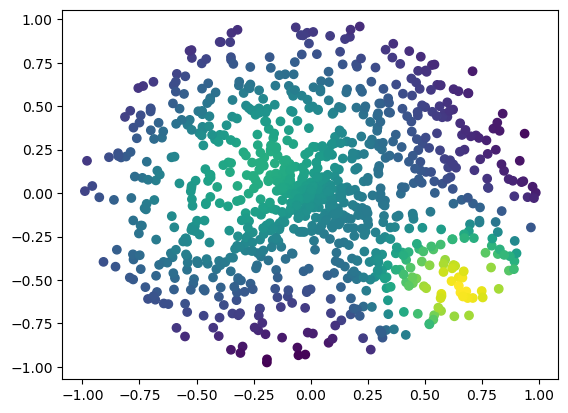

In [551]:
x, theta = gen_data(1000)
rvs = mean_gen(x)
rvs = mean_gen(x)

def mean_(x, theta =None, rvs=rvs):
        
    mu_ = np.sum([rv.pdf(x) for rv in rvs], 0)  

    return mu_

y = mean_(x, theta=None,rvs=rvs)
plt.scatter(x[:,0], x[:,1], c=y)

In [540]:
reglm = LinearRegression()
regt = DecisionTreeRegressor(random_state=0)
regsvr = SVR(C=1.0, epsilon=0.2)
regr = RandomForestRegressor(max_depth=2, random_state=0)
krr = KernelRidge(alpha=1.0)

N, D_in = x.shape
H, D_out = 20, 1
model = TwoLayerNet(D_in, H, D_out)

kernel = 1.0 * RBF(1.0)
gpr = GaussianProcessRegressor(kernel=kernel, random_state=0)

bs = BSplines(x, df=[4]*2, degree=[3]*2)
alpha = np.array([10]*2)
df = pd.DataFrame({'x1':x[:,0], 'x2':x[:,1], 'y':y})

lm_list = []
tree_list = []
svr_list = []
rr_list = []
krr_list = []
gam_list = []
nn_list = []
gp_list = []


for n in trange(10,100):
    idx = np.random.choice(100, n, replace=False)
    reglm.fit(
        x[idx,:], 
        y[idx]
    )
    regt.fit(
        x[idx,:], 
        y[idx]
    )
    regsvr.fit(
        x[idx,:], 
        y[idx]
    )
    regr.fit(
        x[idx,:], 
        y[idx]
    )
    krr.fit(
        x[idx,:], 
        y[idx]
    )
    
    model.fit(
        x[idx,:], 
        y[idx]
    )
    
    gpr.fit(
        x[idx,:], 
        y[idx]
    )
    
    bs = BSplines(x[idx,:], df=[4]*2, degree=[3]*2)
    df = pd.DataFrame({'inter':1,'x1':x[idx,0], 'x2':x[idx,1], 'y':y[idx]})
    gam_bs = GLMGam.from_formula('y ~ inter', data=df,
                                     smoother=bs, alpha=alpha)
    res_gam = gam_bs.fit()


    #lm_list.append(reglm.score(x, y))
    #tree_list.append(regt.score(x, y))
    #svr_list.append(regsvr.score(x, y))
    #rr_list.append(regr.score(x, y))
    
    lm_list.append(np.power(reglm.predict(x) - y, 2).mean())
    tree_list.append(np.power(regt.predict(x) - y, 2).mean())
    svr_list.append(np.power(regsvr.predict(x) - y, 2).mean())
    rr_list.append(np.power(regr.predict(x) - y, 2).mean())
    krr_list.append(np.power(krr.predict(x) - y, 2).mean())
    
    a_min = max(df.min()[1],df.min()[2])
    a_max = min(df.max()[1],df.max()[2])
    df1 = pd.DataFrame({'inter':1,'x1':x[:,0], 'x2':x[:,1], 'y':y})
    gam_list.append(
        np.power(y - res_gam.predict(df1.iloc[:,0], np.clip(df1.iloc[:,1:], a_min=a_min, a_max=a_max)),2).mean()
    )
    
    nn_list.append(np.power(model.predict(x) - y, 2).mean())
    gp_list.append(np.power(gpr.predict(x) - y, 2).mean())

 40%|█████████████████▏                         | 36/90 [00:21<00:31,  1.71it/s]/Users/eochoa/opt/anaconda3/envs/working/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:616: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL_TERMINATION_IN_LNSRCH.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
 58%|████████████████████████▊                  | 52/90 [00:30<00:22,  1.70it/s]/Users/eochoa/opt/anaconda3/envs/working/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:616: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL_TERMINATION_IN_LNSRCH.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
 67%|████████████████████████████▋              | 60/90 [00:35<00:17,  1.67it/s]

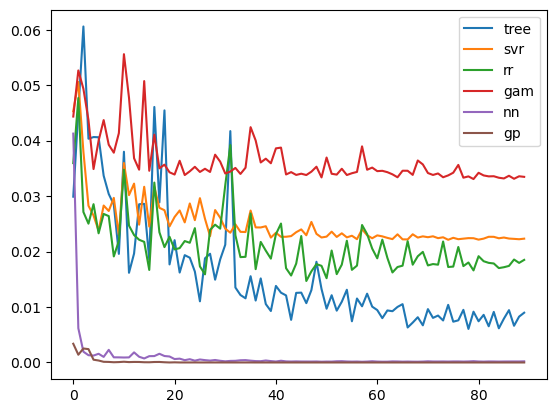

In [555]:
#plt.plot(lm_list, label='lm')
plt.plot(tree_list, label='tree')
plt.plot(svr_list, label='svr')
plt.plot(rr_list, label='rr')
#plt.plot(krr_list, label='krr')
plt.plot(gam_list, label='gam')
plt.plot(nn_list, label='nn')
plt.plot(gp_list, label='gp')

plt.legend()

In [47]:


#regsvr = make_pipeline(StandardScaler(), SVR(C=1.0, epsilon=0.2))


In [528]:
x.shape

(1000, 2)

In [627]:
reglm = LinearRegression()
regt = DecisionTreeRegressor(random_state=0)
regsvr = SVR(C=1.0, epsilon=0.2)
regr = RandomForestRegressor(max_depth=2, random_state=0)

x, _ = gen_data(M, 5, 5)
N, D_in = x.shape
H, D_out = 20, 1
model = TwoLayerNet(D_in, H, D_out)

kernel = 1.0 * RBF(1.0)
gpr = GaussianProcessRegressor(kernel=kernel, random_state=0)

k=10

algos_dict = {
    'Greedy_T': [Greedy_f, {'reg_func':regt, 'k':k}, 100, 'Greedy_T', 'b'], 
    'TS_linear': [TS_linear, {}, 100, 'TS_linear', 'black'],  
    #'Greedy_linear': [Greedy_f, {}, 100, 'Greedy_linear', 'g'], 
    'Greedy_linear': [Greedy_f, {'reg_func':reglm, 'k':k}, 100, 'Greedy_linear', 'g'], 
    'Greedy_RR': [Greedy_f, {'reg_func':regr, 'k':k}, 100, 'Greedy_RR', 'r'], 
    'Greedy_SVM': [Greedy_f, {'reg_func':regsvr, 'k':k}, 100, 'Greedy_SVM', 'y'], 
    #'Greedy_Frechet': [Greedy_Frechet, {'k':20, 'ss':6, 'dim':6, 'supp':None}, 10, 'Greedy_Frechet', 'm'],
    'Greedy_MLP': [Greedy_f, {'reg_func':model, 'k':k}, 100, 'Greedy_MLP', 'gray'], 
    'Greedy_GP': [Greedy_f, {'reg_func':gpr, 'k':k}, 100, 'Greedy_GP', 'lightblue'], 
    
}

In [ ]:
rvs = mean_gen(x)

def mean_(x, theta =None, rvs=rvs):
        
    mu_ = np.sum([rv.pdf(x) for rv in rvs], 0)  

    return mu_

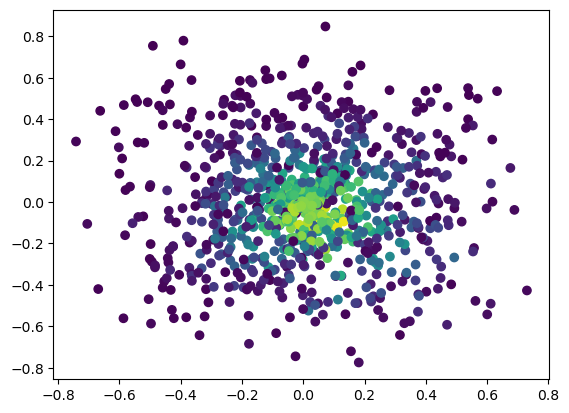

In [622]:
x, theta = gen_data(1000, 5, 5)
rvs = mean_gen(x, n_crit=4)
def mean_(x, theta =None, rvs=rvs):
        
    mu_ = np.sum([rv.pdf(x) for rv in rvs], 0)  

    return mu_

y = mean_(x, theta)
plt.scatter(x[:,0], x[:,1], c=y)

In [628]:
M = 30
T = 100
reg_list = {algo:[] for algo in algos_dict}
rwd_list = {algo:[] for algo in algos_dict}
for trial_idx in trange(5):
    #x, theta = gen_data(M, 5, 5)

    for algo, algo_setup in algos_dict.items():

        n_row, n_col = x.shape[0], 1
        _, n_desc =  x.shape
        cutoff = n_desc
        prob_dict = {
                    "m": n_row,
                    "noise": 0.01,
                    "d": cutoff,
                    "theta": theta,
                    "rwd_func":mean_
                    }
        prob = f_discover(**prob_dict)
        prob.x = x.copy()
            
        t_prob = deepcopy(prob)
        algo_func, algo_params, algo_N_trials, _, _ = algo_setup

        if not trial_idx < algo_N_trials:
            continue
        solver = algo_func(t_prob, **algo_params)
        reg, rwd = solver.run(T)[:2]

        reg_list[algo].append(reg)
        rwd_list[algo].append(np.cumsum(rwd))


  0%|                                                     | 0/5 [00:00<?, ?it/s]/Users/eochoa/opt/anaconda3/envs/working/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:420: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/eochoa/opt/anaconda3/envs/working/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:616: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL_TERMINATION_IN_LNSRCH.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/Users/eochoa/opt/anaconda3/envs/working/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:420: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close

/Users/eochoa/opt/anaconda3/envs/working/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:616: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL_TERMINATION_IN_LNSRCH.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/Users/eochoa/opt/anaconda3/envs/working/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:616: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL_TERMINATION_IN_LNSRCH.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/Users/eochoa/opt/anaconda3/envs/working/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:420: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 1

/Users/eochoa/opt/anaconda3/envs/working/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:616: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL_TERMINATION_IN_LNSRCH.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/Users/eochoa/opt/anaconda3/envs/working/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:420: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/eochoa/opt/anaconda3/envs/working/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:420: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again 

/Users/eochoa/opt/anaconda3/envs/working/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:616: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL_TERMINATION_IN_LNSRCH.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/Users/eochoa/opt/anaconda3/envs/working/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:420: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/eochoa/opt/anaconda3/envs/working/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:430: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__constant_value is close to the specified upper bound 100000.0. Increasing the bound and calling fit a

/Users/eochoa/opt/anaconda3/envs/working/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:616: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL_TERMINATION_IN_LNSRCH.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/Users/eochoa/opt/anaconda3/envs/working/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:616: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL_TERMINATION_IN_LNSRCH.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/Users/eochoa/opt/anaconda3/envs/working/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:430: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__constant_value is close to the specified upper bound

...

/Users/eochoa/opt/anaconda3/envs/working/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:616: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL_TERMINATION_IN_LNSRCH.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/Users/eochoa/opt/anaconda3/envs/working/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:616: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL_TERMINATION_IN_LNSRCH.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/Users/eochoa/opt/anaconda3/envs/working/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:420: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 1

 80%|████████████████████████████████████         | 4/5 [03:53<00:58, 58.76s/it]/Users/eochoa/opt/anaconda3/envs/working/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:420: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/eochoa/opt/anaconda3/envs/working/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:420: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/eochoa/opt/anaconda3/envs/working/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:420: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 1e-05. Decreasing t

/Users/eochoa/opt/anaconda3/envs/working/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:430: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__constant_value is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/eochoa/opt/anaconda3/envs/working/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:420: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/eochoa/opt/anaconda3/envs/working/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:430: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__constant_value is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.war

/Users/eochoa/opt/anaconda3/envs/working/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:616: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL_TERMINATION_IN_LNSRCH.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/Users/eochoa/opt/anaconda3/envs/working/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:430: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__constant_value is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/eochoa/opt/anaconda3/envs/working/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:420: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit a

/Users/eochoa/opt/anaconda3/envs/working/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:616: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL_TERMINATION_IN_LNSRCH.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/Users/eochoa/opt/anaconda3/envs/working/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:616: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL_TERMINATION_IN_LNSRCH.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/Users/eochoa/opt/anaconda3/envs/working/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:430: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__constant_value is close to the specified upper bound

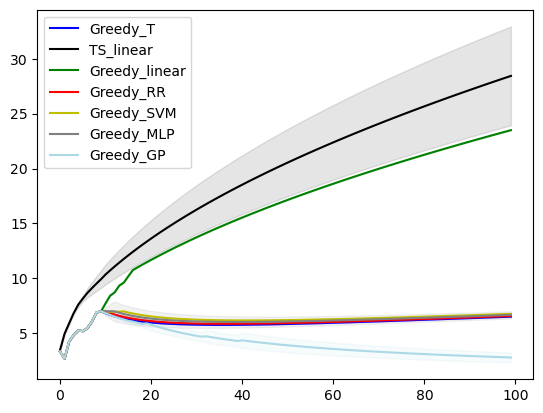

In [631]:
m = 0
n = 1000
alpha = 0.5
for algo in algos_dict:
    algo_label = algos_dict[algo][3]
    algo_style = algos_dict[algo][4]
    y_ = np.mean(reg_list[algo], axis = 0)[m:n]
    y_ = y_ / np.power((np.ones(y_.shape[0])).cumsum(), alpha)
    ci = np.std(reg_list[algo], axis = 0)[m:n]/ np.power((np.ones(y_.shape[0])).cumsum(), alpha)
    plt.plot(range(y_.shape[0]), y_,
                  algo_style, label=algo_label)
    plt.fill_between(range(y_.shape[0]), (y_-ci), (y_+ci), color = algo_style, alpha=.1)

    plt.legend()

KeyError: 'Greedy_GP'

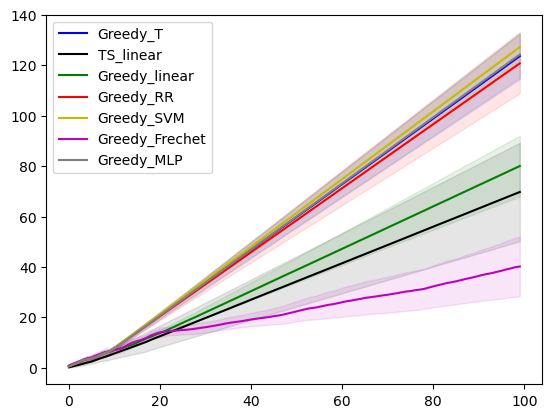

In [560]:
alpha = 0
for algo in algos_dict:
    algo_label = algos_dict[algo][3]
    algo_style = algos_dict[algo][4]
    y_ = np.mean(rwd_list[algo], axis = 0)[:1000]
    y_ = y_ / np.power((np.ones(y_.shape[0])).cumsum(), alpha)
    ci = np.std(rwd_list[algo], axis = 0)[:1000]/ np.power((np.ones(y_.shape[0])).cumsum(), alpha)
    plt.plot(range(y_.shape[0]), y_,
                  algo_style, label=algo_label)
    plt.fill_between(range(y_.shape[0]), (y_-ci), (y_+ci), color = algo_style, alpha=.1)

    plt.legend()

In [96]:
#p = np.random.rand(5)
p = np.ones(5) / 5

In [97]:
P = sklearn.metrics.pairwise_distances(x[:5])
P = ((1 - P / P.max(1)[:,None]) * p)
P = P / P.sum(1)[:,None]
P.sum(1)

array([1., 1., 1., 1., 1.])

In [102]:
Pn = P.copy()
for i in range(50):
    Pn = P @ Pn

In [120]:
np.concatenate([x[:5], x[:5].mean(0)[None,:]])

array([[-0.51387429, -0.4858232 ],
       [-0.09208713, -0.16469393],
       [ 0.05528665,  0.20329398],
       [-0.12640135,  0.8244633 ],
       [-0.72410064, -0.09601115],
       [-0.28023535,  0.0562458 ]])

In [136]:
np.sum(sklearn.metrics.pairwise_distances(np.concatenate([x[:5], x[:5].mean(0)[None,:]]))[5,:]/0.7834685880545222)

3.1903325669171547

In [145]:
(1-sklearn.metrics.pairwise_distances(np.concatenate([x[:5], x[:5].mean(0)[None,:]]))[5,:])/2.45

array([0.16723422, 0.28971564, 0.25864053, 0.08838017, 0.21663134,
       0.40816327])

In [104]:
Pn

array([[0.16660138, 0.28472143, 0.28219533, 0.08207662, 0.18440524],
       [0.16660138, 0.28472143, 0.28219533, 0.08207662, 0.18440524],
       [0.16660138, 0.28472143, 0.28219533, 0.08207662, 0.18440524],
       [0.16660138, 0.28472143, 0.28219533, 0.08207662, 0.18440524],
       [0.16660138, 0.28472143, 0.28219533, 0.08207662, 0.18440524]])

In [98]:
#pd.DataFrame((1 - P / P.max(1)))
pd.DataFrame(P)

,0,1,2,3,4
0,0.379683,0.232375,0.131326,0.000000,0.256616
1,0.191773,0.412956,0.247565,0.000000,0.147707
2,0.000000,0.293156,0.526800,0.145335,0.034710
3,0.000000,0.137904,0.263335,0.500311,0.098450
4,0.264330,0.186460,0.106045,0.000000,0.443165


In [87]:
P

array([[0.        , 0.53012113, 0.89377103, 1.36637696, 0.44288661],
       [0.53012113, 0.        , 0.39640148, 0.98975224, 0.63573454],
       [0.89377103, 0.39640148, 0.        , 0.64719537, 0.83488209],
       [1.36637696, 0.98975224, 0.64719537, 0.        , 1.0975052 ],
       [0.44288661, 0.63573454, 0.83488209, 1.0975052 , 0.        ]])

In [88]:
P / P.max(1)[:,None]

array([[0.        , 0.38797575, 0.65411747, 1.        , 0.32413208],
       [0.53560993, 0.        , 0.40050577, 1.        , 0.64231685],
       [1.        , 0.4435157 , 0.        , 0.72411764, 0.93411183],
       [1.        , 0.72436251, 0.47365799, 0.        , 0.80322285],
       [0.40353942, 0.57925424, 0.76070901, 1.        , 0.        ]])

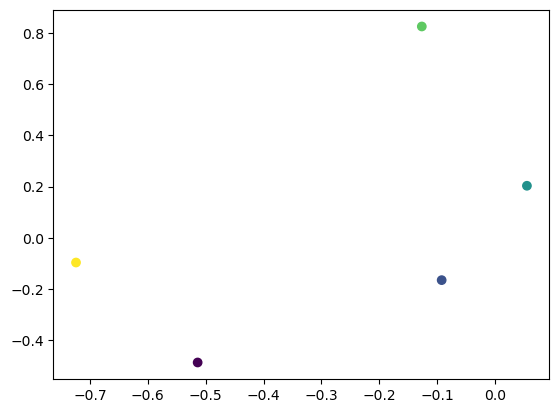

In [83]:
plt.scatter(x[:5,0], x[:5,1], c=range(5))

In [65]:
import torch
from torch import nn
import math
import time

In [308]:
y = np.random.normal(np.power(x, 3)@ theta , 0.1)

In [314]:
model.fit(x=x, y=y)

In [315]:
((model.predict(x=x) - torch.tensor(y)) ** 2).sum()

tensor(0.1907, dtype=torch.float64)